Loading

In [ ]:

import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import logging
logging.getLogger().setLevel(logging.ERROR) 
basepath = r"Z:\Data\AYAold\AYA10\day27"
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='pyr'

basename=os.path.basename(basepath)# Define the new folder path
# Working folder
new_folder_path = os.path.join(basepath, "complex_system")
path_parts = basepath.split("\\")  # Split the path on backslashes
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# # load in spike data from hpc pyramidal cells
# st, cm = loading.load_spikes(
#     basepath,putativeCellType="Pyr",brainRegion=brain_region #putativeCellType="Pyr|"
# )
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
# theta_epochs = nel.EpochArray(
#     state_dict["THETA"],
# )
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
#spike_times = st.data[(cm.firingRate > 0.2) & (cm.shankID < 5)][:]
# spike_times = st.data[(cm.firingRate > 0.2)][:]

# spike_times.shape

Folder already exists: Z:\Data\AYAold\AYA10\day27\complex_system


In [2]:
import numpy as np
import pandas as pd
import os
from criticality import WiltingPriesemann as WP
import pickle
import tempfile
import time
# Function to convert spike train data to a binary spike matrix
def convert_spike_times_to_matrix(spike_times, bin_size, total_time):
    """
    Converts spike times into a binary spike matrix using vectorized operations.

    Parameters:
    - spike_times: List of arrays, where each array contains spike times (in seconds) for a neuron.
    - bin_size: Size of each time bin (in seconds or milliseconds).
    - total_time: Total duration of the recording (in seconds or milliseconds).

    Returns:
    - spike_matrix: Binary matrix of shape (num_units, num_bins), where 1 indicates a spike in the bin.
    - time_stamps: Array of time stamps corresponding to the center of each bin.
    """
    bin_size = float(bin_size)  # Ensure bin_size is a float
    num_units = len(spike_times)
    num_bins = int(np.ceil(total_time / bin_size))  # Total number of bins

    # Precompute bin edges
    bin_edges = np.arange(0, total_time + bin_size, bin_size)

    # Flatten spike_times for vectorized processing
    all_spikes = np.concatenate(spike_times)
    all_units = np.concatenate([[i] * len(spikes) for i, spikes in enumerate(spike_times)])

    # Convert spike times to bin indices
    bin_indices = np.digitize(all_spikes, bin_edges) - 1  # Digitize returns 1-based indices
    valid_indices = bin_indices[bin_indices < num_bins]  # Exclude out-of-range spikes
    valid_units = all_units[bin_indices < num_bins]

    # Create the spike matrix using sparse representation for efficiency
    spike_matrix = np.zeros((num_units, num_bins), dtype=int)
    np.add.at(spike_matrix, (valid_units, valid_indices), 1)

    # Compute time stamps (center of each bin)
    time_stamps = np.arange(num_bins) * bin_size + (bin_size / 2)

    return spike_matrix, time_stamps

def split_intervals_into_subintervals(time_intervals, min_length=2):
    """
    Splits each interval into 10-second subintervals, discarding smaller subintervals.

    Parameters:
    - time_intervals: List of intervals, where each interval is [start, end].
    - min_length: Minimum length of subintervals in seconds.

    Returns:
    - subintervals: List of 10-second subintervals.
    """
    subintervals = []
    for start, end in time_intervals:
        current_start = start
        while current_start + min_length <= end:
            subintervals.append([current_start, current_start + min_length])
            current_start += min_length
            # Check if the last subinterval is too short and discard it
    return subintervals
def extract_spike_matrix_by_intervals(spike_matrix, time_stamps, time_intervals):
    """
    Extracts spike matrices for specific time intervals.

    Parameters:
    - spike_matrix: Binary matrix (units x bins).
    - time_stamps: Array of time stamps corresponding to the columns of spike_matrix.
    - time_intervals: List of intervals, where each interval is [start, end].

    Returns:
    - interval_matrices: List of submatrices for each interval.
    - interval_indices: List of indices corresponding to the time intervals.
    """
    interval_matrices = []
    interval_indices = []

    for start, end in time_intervals:
        # Find indices of time stamps within the interval
        indices = np.where((time_stamps >= start) & (time_stamps < end))[0]
        if len(indices) > 0:
            # Extract submatrix for the interval
            submatrix = spike_matrix[:, indices]
            interval_matrices.append(submatrix)
            interval_indices.append(indices)
        else:
            print(f"No spikes found for interval [{start}, {end}]")
    return interval_matrices, interval_indices


def compute_and_plot_branching_ratios(interval_matrices, time_intervals, k_max=100, output_dir="branching_ratio_plots"):
    """
    Computes and plots branching ratios for each subinterval.

    Parameters:
    - interval_matrices: List of spike matrices for each subinterval.
    - time_intervals: List of subintervals corresponding to the matrices.
    - k_max: Maximum time lag for branching ratio calculation.
    - output_dir: Directory to save plots.

    Returns:
    - branching_ratios: List of branching ratios for each subinterval.
    """
    branching_ratios = []
    results = []
    centers=[]
    Goodfit=[]
    for i, (matrix, interval) in enumerate(zip(interval_matrices, time_intervals)):
        # Compute activity vector (number of active neurons per time bin)
        A_t = np.count_nonzero(matrix, axis=0)

        # Skip intervals with insufficient activity
        if len(A_t) < 2:
            print(f"Insufficient data in subinterval {interval} for branching ratio computation.")
            branching_ratios.append(None)
            continue
        
        # Use WP.MR_estimation to compute branching ratio
        mr_result = WP.MR_estimation(A_t, k_max)
                # Compute the center of the interval
        center = (interval[0] + interval[1]) / 2
        
        branching_ratio = mr_result['branching_ratio']
        k = mr_result['k']
        rk_data = mr_result['r_k']
        b = mr_result['p_opt'][0]  # Fitted b
        m = mr_result['p_opt'][1]  # Fitted m

        # Evaluate the fit
        metrics, rk_model = evaluate_wilting_priesemann_fit(k, rk_data, b, m)
        # Save the results
        centers.append(center)
        branching_ratios.append(branching_ratio)
        Goodfit.append(metrics)
        
        # Plot the branching ratio for this subinterval
        #plot_branching_ratio(mr_result, interval, i, output_dir)
        if i % 50 == 0:  # Plot every 10th interval
            plot_branching_ratio(mr_result, interval, i, output_dir)
    results={"centers": centers, "branching_ratios": branching_ratios,"Goodfit":  Goodfit}
    return results
def split_intervals_into_sliding_windows(time_intervals, window_size, step_size):
    """
    Splits each interval into overlapping sliding windows.

    Parameters:
    - time_intervals: List of intervals, where each interval is [start, end].
    - window_size: Size of the sliding window in seconds.
    - step_size: Step size for the sliding window in seconds.

    Returns:
    - sliding_windows: List of sliding windows as [start, end].
    """
    sliding_windows = []
    for start, end in time_intervals:
        current_start = start
        while current_start + window_size <= end:
            sliding_windows.append([current_start, current_start + window_size])
            current_start += step_size
    return sliding_windows


def extract_spike_matrix_by_sliding_windows(spike_matrix, time_stamps, sliding_windows):
    """
    Extracts spike matrices for each sliding window.

    Parameters:
    - spike_matrix: Binary matrix (units x bins).
    - time_stamps: Array of time stamps corresponding to the columns of spike_matrix.
    - sliding_windows: List of sliding windows, where each window is [start, end].

    Returns:
    - window_matrices: List of spike matrices for each sliding window.
    - window_centers: List of centers for each sliding window.
    """
    window_matrices = []
    window_centers = []

    for start, end in sliding_windows:
        # Find indices of time stamps within the window
        indices = np.where((time_stamps >= start) & (time_stamps < end))[0]
        if len(indices) > 0:
            # Extract submatrix for the window
            submatrix = spike_matrix[:, indices]
            window_matrices.append(submatrix)
            window_centers.append((start + end) / 2)  # Center of the window
        else:
            print(f"No spikes found for sliding window [{start}, {end}]")
    
    return window_matrices, window_centers
# Function to plot regression coefficients and fitted MR model
def plot_branching_ratio(mr_data, title, filename):
    plt.figure(figsize=(8, 6))
    plt.plot(mr_data['k'], mr_data['r_k'], 'o', label="Data (r_k)", color="blue")
    plt.plot(mr_data['k'], mr_data['fitfunc'](mr_data['k'], *mr_data['p_opt']), '-', label="Fitted Model", color="green")
    plt.xlabel("Time Lag (k)")
    plt.ylabel("Regression Coefficient (r_k)")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"branching_ratio_plot_{filename}.png")
    plt.show()


def plot_branching_ratio(mr_result, interval, interval_idx, output_dir):
    """
    Plots the branching ratio (r_k vs k) and the fitted model for a given interval.

    Parameters:
    - mr_result: Result of WP.MR_estimation, containing r_k, k, fitfunc, and branching ratio.
    - interval: Time interval [start, end] for which the branching ratio was computed.
    - interval_idx: Index of the interval (used for file naming and titles).
    - output_dir: Directory to save the plot.
    """
    if mr_result is None:
        print(f"No branching ratio computed for interval {interval}.")
        return
    
    # Extract data for plotting
    k = mr_result['k']
    r_k = mr_result['r_k']
    fitted_r_k = mr_result['fitfunc'](k, *mr_result['p_opt'])  # Fitted curve
    
    # Plot the results
    plt.figure(figsize=(8, 6))
    plt.plot(k, r_k, 'o', label="Data (r_k)", color="blue")
    plt.plot(k, fitted_r_k, '-', label="Fitted Model", color="green")
    plt.xlabel("Time Lag (k)")
    plt.ylabel("Regression Coefficient (r_k)")
    plt.title(f"Branching Ratio for Interval {interval} (Index {interval_idx})")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    # Save the plot in the subfolder
    os.makedirs(output_dir, exist_ok=True)
    folder_name = f"{animal_name}_{day}_{brain_region}"
    folder_path = os.path.join(output_dir, folder_name)
    os.makedirs(folder_path, exist_ok=True)
    plot_path = os.path.join(folder_path, f"branching_ratio_interval_{interval_idx}.png")
    plt.savefig(plot_path)
    plt.close()  # Close the plot to save memory

import numpy as np

def evaluate_wilting_priesemann_fit(k, rk_data, b, m,k_max=50, n_shuffles=100):
    """
    Evaluates the goodness-of-fit for the Wilting & Priesemann branching ratio model.

    Parameters:
    - k: Array of time lags (k).
    - rk_data: Array of observed regression coefficients (r_k).
    - b: Fitted parameter for the model.
    - m: Fitted branching ratio.
    
    Returns:
    - metrics: Dictionary with R^2, RMSE, and residuals.
    """
    # Predicted r_k values from the model
    mask = k <= k_max
    k_subset = k[mask]
    rk_data_subset = rk_data[mask]
    
    # Predicted r_k values from the model
    rk_model = b * (m ** k)
    rk_model_subset = rk_model[mask]
    
    # Residuals for the subset
    residuals_subset = rk_data_subset - rk_model_subset
    
    # Total Sum of Squares (SS_tot) for the subset
    mean_rk_data_subset = np.mean(rk_data_subset)
    ss_tot_subset = np.sum((rk_data_subset - mean_rk_data_subset)**2)
     # Shuffle baseline
    shuffle_r2_values = []
    for _ in range(n_shuffles):
        shuffled_data = np.random.permutation(rk_data_subset)  # Shuffle subsampled data
        residuals_shuffle = shuffled_data - rk_model_subset
        ss_res_shuffle = np.sum(residuals_shuffle**2)
        r2_shuffle = 1 - (ss_res_shuffle / ss_tot_subset) if ss_tot_subset > 0 else None
        shuffle_r2_values.append(r2_shuffle)

    r2_shuffle_mean = np.mean(shuffle_r2_values)
    if np.isclose(ss_tot_subset, 0):
        r2 = None  # Handle undefined case
    else:
        # Residual Sum of Squares (SS_res) for the subset
        ss_res_subset = np.sum(residuals_subset**2)
        # R^2 for the subset
        r2 = 1 - (ss_res_subset / ss_tot_subset)
        if r2 < 0:
                r2 = None
        
    # RMSE for the subset
    rmse_subset = np.sqrt(np.mean(residuals_subset**2))
    
    metrics = {
        "R2": r2,
        "RMSE": rmse_subset,
        "Residuals": residuals_subset,
        "R2_Shuffle": r2_shuffle_mean,
        "R2_Shuffle_Baseline_Distribution": shuffle_r2_values,
    }
    return metrics, rk_model
import os, pickle, tempfile
from datetime import datetime

def save_results_to_pickle(base_dir, animal_name, day, brain_region, results, prefix=None):
    """
    Save `results` to a single pickle file named:
        [{prefix}_]<animal_name>_<day>_<brain_region>.pkl
    using an atomic write (temp file + os.replace).

    Example filename: branching_ratio_MouseA_2024-07-18_CA1.pkl
    """
    os.makedirs(base_dir, exist_ok=True)

    # normalize parts
    animal_str = str(animal_name).strip()
    day_str    = str(day).strip()
    region_str = str(brain_region).strip().upper()

    # optional prefix (e.g., "branching_ratio")
    stem = f"{animal_str}_{day_str}_{region_str}"
    if prefix:
        stem = f"{prefix}_{stem}"

    final_path = os.path.join(base_dir, f"{stem}.pkl")

    # metadata stored with the results
    payload = {
        "results": results,
        "meta": {
            "animal_name": animal_str,
            "day": day_str,
            "brain_region": region_str,
            "saved_at": datetime.utcnow().isoformat() + "Z",
        }
    }

    # atomic write
    fd, tmp_path = tempfile.mkstemp(prefix=stem + "_", suffix=".tmp", dir=base_dir)
    try:
        with os.fdopen(fd, "wb") as f:
            pickle.dump(payload, f, protocol=pickle.HIGHEST_PROTOCOL)
            f.flush()
            os.fsync(f.fileno())
        # atomic replace (works across platforms)
        os.replace(tmp_path, final_path)
        print(f"✅ Saved: {final_path}")
        return final_path
    except Exception as e:
        # clean up temp on failure
        try:
            if os.path.exists(tmp_path):
                os.remove(tmp_path)
        except Exception:
            pass
        raise e

import os
import pickle




In [257]:
# ## Define parameters
# bin_size =0.004   # Time bin size (in ms)
# alpha = 0.01  # Subsampling fraction
# k_max = 100  # Maximum time lag for MR estimation

# epoch_df = loading.load_epoch(basepath)

# all_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)            
#             # Convert spike times to binary spike matrix
# spike_matrix,times_tamps = convert_spike_times_to_matrix(spike_times, bin_size, int(np.max(all_epochs.data)))   
        

In [258]:
# example Z:\Data\AYAold\AYA10\day27

With small time bins= 2sec

In [3]:
import numpy as np
import os
import matplotlib.pyplot as plt
def pad_intervals(iv, pad):
    iv = np.asarray(iv, float)
    if iv.size == 0:
        return np.empty((0,2), float)
    out = iv.copy()
    out[:, 0] -= pad
    out[:, 1] += pad
    out[:, 0] = np.maximum(out[:, 0], 0.0)
    return out

def merge_intervals(iv):
    iv = np.asarray(iv, float)
    if iv.size == 0:
        return np.empty((0,2), float)
    iv = iv[np.argsort(iv[:, 0])]
    merged = [iv[0].tolist()]
    for s, e in iv[1:]:
        if s <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    return np.asarray(merged, float)

GUARD_SEC = 5.0  # 5-second guard

def shrink_intervals(iv, guard):
    iv = np.asarray(iv, float)
    if iv.size == 0: return np.empty((0,2), float)
    iv = np.c_[iv[:,0] + guard, iv[:,1] - guard]
    return iv[iv[:,1] > iv[:,0]]

def intersect_intervals(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    if a.size == 0 or b.size == 0: return np.empty((0,2), float)
    a = a[np.argsort(a[:,0])]; b = b[np.argsort(b[:,0])]
    out = []; ia = ib = 0
    while ia < len(a) and ib < len(b):
        s = max(a[ia,0], b[ib,0]); e = min(a[ia,1], b[ib,1])
        if e > s: out.append([s,e])
        if a[ia,1] < b[ib,1]: ia += 1
        else: ib += 1
    return np.array(out, float) if out else np.empty((0,2), float)

def subtract_intervals(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    if a.size == 0: return np.empty((0,2), float)
    if b.size == 0: return a.copy()
    out = []
    for s,e in a:
        cur = s
        for s2,e2 in b:
            if e2 <= cur or s2 >= e: continue
            if s2 > cur: out.append([cur, min(s2, e)])
            cur = max(cur, e2)
            if cur >= e: break
        if cur < e: out.append([cur,e])
    return np.array(out, float) if out else np.empty((0,2), float)

import os, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nelpy as nel
from neuro_py.io import loading
RIPPLE_PAD_SEC = 0.05  # 50 ms padding around ripple start/stop (tune 0–0.2)
ABLATE_RIPPLES = True

#================== CONFIG ==================
paths = [
    # r"W:\data\PPP\PPP20\day4",
    # r"W:\data\PPP\PPP20\day5",
    # r"W:\data\PPP\PPP21\day5",
    # r"W:\data\PPP\PPP21\day4",
    # r"W:\data\PPP\PPP8\day8",
    # r"W:\data\PPP\PPP4\day11",
    r"W:\data\PPP\PPP7\day7",
    # r"W:\data\PPP\PPP7\day12",
    # r"W:\data\PPP\PPP7\day10",
    # r"W:\data\PPP\PPP23\day8",
    # r"X:\data\Barrage\NN8\day7",
    # r"X:\data\Barrage\NN3\day15",
    # r"X:\data\Barrage\NN2\day24",
    # r"X:\data\Barrage\NN2\day10",
    # r"W:\data\PPP\CA2\PPP7\day12",
    # r"X:\data\Barrage\NN2\day10_3",
    # r"X:\data\Barrage\NN3\day12",
    # r"X:\data\Barrage\NN3\day16",
    # r"X:\data\Barrage\NN3\day25",
    # r"X:\data\Barrage\NN8\day6",
    # r"X:\data\Barrage\NN16\day13",
]

OUTDIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\branching_ratio\ablate_ripple"
Path(OUTDIR).mkdir(parents=True, exist_ok=True)

GUARD_SEC   = 5.0
WINDOW_SIZE = 10
STEP_SIZE   = 2
K_MAX       = 200
BIN_SIZE    = 0.003 # seconds
DEFAULT_REGION = "CA1"

# ============= helper: region inference =============
def infer_region(basepath, default="CA1"):
    return "CA2" if ("\\CA2\\" in basepath or "/CA2/" in basepath) else default

def shrink_intervals(iv, guard):
    iv = np.asarray(iv, float)
    if iv.size == 0: return np.empty((0,2), float)
    iv = np.c_[iv[:,0]+guard, iv[:,1]-guard]
    return iv[iv[:,1] > iv[:,0]]

# (uses intersect_intervals and subtract_intervals)

# ============= main batch loop =============
for basepath in paths:
    parts = basepath.replace("/", "\\").split("\\")
    animal_name = parts[-2]
    day = parts[-1]
    brain_region = infer_region(basepath, DEFAULT_REGION)

    print(f"\n=== {animal_name} {day} [{brain_region}] ===")

    try:
        # ---------- Load data ----------
        st, cm = loading.load_spikes(basepath, putativeCellType="Pyr", brainRegion=brain_region)
        state_dict = loading.load_SleepState_states(basepath)
        epoch_df = loading.load_epoch(basepath)
        # ---------- Load ripples ----------
        ripple_iv = np.empty((0, 2), float)
        try:
            ripple_events = loading.load_ripples_events(basepath=basepath)
            ripple_iv = np.c_[np.asarray(ripple_events.start, float),
                            np.asarray(ripple_events.stop,  float)]
            ripple_iv = ripple_iv[np.isfinite(ripple_iv).all(axis=1)]
            if ripple_iv.size:
                ripple_iv = pad_intervals(ripple_iv, RIPPLE_PAD_SEC)
                ripple_iv = merge_intervals(ripple_iv)
            print(f"  Ripples loaded: {len(ripple_iv)} intervals (pad={RIPPLE_PAD_SEC}s)")
        except Exception as e:
            print(f"  [warn] could not load ripples: {e}")
            ripple_iv = np.empty((0, 2), float)

        ripple_epochs = nel.EpochArray(ripple_iv) if ripple_iv.size else None

        all_epochs = nel.EpochArray(np.c_[epoch_df.startTime.values, epoch_df.stopTime.values])
        total_time = float(np.nanmax(all_epochs.data)) if all_epochs.data.size else float(np.nanmax(st.data))
        spike_times = st.data[(cm.firingRate > 0.2)]
        spike_matrix, time_stamps = convert_spike_times_to_matrix(spike_times, BIN_SIZE, total_time)

        # ---------- Guard and state setup ----------
        nrem = shrink_intervals(state_dict["NREMstate"], GUARD_SEC)
        wake = shrink_intervals(state_dict["WAKEstate"], GUARD_SEC)
        if state_dict.get("THETA") is None or len(state_dict.get("THETA", [])) == 0:
            print("  [skip] No THETA epochs found.")
            theta = np.empty((0,2), float)
        else:
            theta = shrink_intervals(state_dict["THETA"], GUARD_SEC)
        rem = shrink_intervals(state_dict["REMstate"], GUARD_SEC)
        wake_theta = intersect_intervals(wake, theta)
        wake_nontheta = subtract_intervals(wake, theta)

        state_intervals = {
            "NREM": nrem,
            "REM": rem,
            "THETA": wake_theta,
            "nonTHETA": wake_nontheta,
        }
        # ---------- Ablate ripple time from each state's intervals ----------
        state_intervals_noRipple = {}
        if ABLATE_RIPPLES and ripple_iv.size:
            for k, iv in state_intervals.items():
                state_intervals_noRipple[k] = subtract_intervals(iv, ripple_iv)
        else:
            for k, iv in state_intervals.items():
                state_intervals_noRipple[k] = iv.copy()

        # ---------- Compute all states ----------
        results_all_states = {"meta": {
            "animal": animal_name,
            "day": day,
            "brain_region": brain_region,
            "guard_sec": GUARD_SEC,
            "bin_size": BIN_SIZE,
            "window_size": WINDOW_SIZE,
            "step_size": STEP_SIZE,
            "k_max": K_MAX,
            "ripple_pad_sec": RIPPLE_PAD_SEC,
            "ablate_ripples": ABLATE_RIPPLES,

        }}
        plot_dir = os.path.join(OUTDIR, "branching_ratio_slidingwindow_plots",)
        Path(plot_dir).mkdir(exist_ok=True)

        for state_name in state_intervals.keys():

            # ---------- A) With ripples (original intervals) ----------
            intervals = state_intervals[state_name]
            if intervals is not None and len(intervals) > 0:
                sliding_windows = split_intervals_into_sliding_windows(
                    intervals, window_size=WINDOW_SIZE, step_size=STEP_SIZE
                )
                if len(sliding_windows) > 0:
                    window_mats, centers = extract_spike_matrix_by_sliding_windows(
                        spike_matrix, time_stamps, sliding_windows
                    )
                    if len(window_mats) > 0:
                        print(f"  Computing {state_name} WITH ripples ({len(window_mats)} windows)")
                        res = compute_and_plot_branching_ratios(
                            window_mats, sliding_windows, k_max=K_MAX, output_dir=plot_dir
                        )
                        res["centers"] = centers
                        res["guard_sec"] = GUARD_SEC
                        res["ripple_pad_sec"] = RIPPLE_PAD_SEC
                        res["n_ripple_intervals"] = int(len(ripple_iv))
                        results_all_states[state_name] = res
                    else:
                        print(f"[skip] {state_name} WITH: no spikes found in windows")
                else:
                    print(f"[skip] {state_name} WITH: no windows after split")
            else:
                print(f"[skip] {state_name} WITH: no intervals")

            # ---------- B) No-ripple (ablated intervals) ----------
            intervals_nr = state_intervals_noRipple[state_name]
            key_nr = f"{state_name}_noRipple"
            if intervals_nr is not None and len(intervals_nr) > 0:
                sliding_windows = split_intervals_into_sliding_windows(
                    intervals_nr, window_size=WINDOW_SIZE, step_size=STEP_SIZE
                )
                if len(sliding_windows) > 0:
                    window_mats, centers = extract_spike_matrix_by_sliding_windows(
                        spike_matrix, time_stamps, sliding_windows
                    )
                    if len(window_mats) > 0:
                        print(f"  Computing {state_name} NO ripples ({len(window_mats)} windows)")
                        res = compute_and_plot_branching_ratios(
                            window_mats, sliding_windows, k_max=K_MAX, output_dir=plot_dir
                        )
                        res["centers"] = centers
                        res["guard_sec"] = GUARD_SEC
                        res["ripple_pad_sec"] = RIPPLE_PAD_SEC
                        res["n_ripple_intervals"] = int(len(ripple_iv))
                        res["note"] = "Ripple time removed (start/stop padded) before windowing."
                        results_all_states[key_nr] = res
                    else:
                        print(f"[skip] {state_name} NO: no spikes found in windows")
                else:
                    print(f"[skip] {state_name} NO: no windows after split")
            else:
                print(f"[skip] {state_name} NO: no intervals after ripple ablation")


        # ---------- Save combined PKL ----------
        fname = f"branching_ratio_allstates_win{WINDOW_SIZE}s_step{STEP_SIZE}s_guard{int(GUARD_SEC)}s_{animal_name}_{day}_{brain_region}.pkl"
        save_path = os.path.join(OUTDIR, fname)
        with open(save_path, "wb") as f:
            pickle.dump(results_all_states, f, protocol=pickle.HIGHEST_PROTOCOL)

        print(f"✅ Saved combined results: {save_path}")

    except Exception as e:
        print(f"[ERROR] {basepath}: {e}")
        continue





=== PPP7 day7 [CA1] ===
  Ripples loaded: 15856 intervals (pad=0.05s)
  Computing NREM WITH ripples (5876 windows)
  Computing NREM NO ripples (49 windows)
  Computing REM WITH ripples (251 windows)
  Computing REM NO ripples (68 windows)
  Computing THETA WITH ripples (234 windows)
  Computing THETA NO ripples (87 windows)
  Computing nonTHETA WITH ripples (4851 windows)
  Computing nonTHETA NO ripples (539 windows)
✅ Saved combined results: D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\branching_ratio\ablate_ripple\branching_ratio_allstates_win10s_step2s_guard5s_PPP7_day7_CA1.pkl

=== PPP23 day10 [CA1] ===


D:\Documents\GitHub\neuro_py\neuro_py\io\loading.py:858: UserWarning: file does not exist


  [warn] could not load ripples: 'DataFrame' object has no attribute 'start'
  Computing NREM WITH ripples (5339 windows)
  Computing NREM NO ripples (5339 windows)
  Computing REM WITH ripples (182 windows)
  Computing REM NO ripples (182 windows)
  Computing THETA WITH ripples (261 windows)
  Computing THETA NO ripples (261 windows)
  Computing nonTHETA WITH ripples (5999 windows)


D:\Documents\GitHub\Sleep_criticaltiy\src\criticality\WiltingPriesemann.py:199: RuntimeWarning: invalid value encountered in log


  Computing nonTHETA NO ripples (5999 windows)
✅ Saved combined results: D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\branching_ratio\ablate_ripple\branching_ratio_allstates_win10s_step2s_guard5s_PPP23_day10_CA1.pkl


In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt

GUARD_SEC = 5.0  # 5-second guard

def shrink_intervals(iv, guard):
    iv = np.asarray(iv, float)
    if iv.size == 0: return np.empty((0,2), float)
    iv = np.c_[iv[:,0] + guard, iv[:,1] - guard]
    return iv[iv[:,1] > iv[:,0]]

def intersect_intervals(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    if a.size == 0 or b.size == 0: return np.empty((0,2), float)
    a = a[np.argsort(a[:,0])]; b = b[np.argsort(b[:,0])]
    out = []; ia = ib = 0
    while ia < len(a) and ib < len(b):
        s = max(a[ia,0], b[ib,0]); e = min(a[ia,1], b[ib,1])
        if e > s: out.append([s,e])
        if a[ia,1] < b[ib,1]: ia += 1
        else: ib += 1
    return np.array(out, float) if out else np.empty((0,2), float)

def subtract_intervals(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    if a.size == 0: return np.empty((0,2), float)
    if b.size == 0: return a.copy()
    out = []
    for s,e in a:
        cur = s
        for s2,e2 in b:
            if e2 <= cur or s2 >= e: continue
            if s2 > cur: out.append([cur, min(s2, e)])
            cur = max(cur, e2)
            if cur >= e: break
        if cur < e: out.append([cur,e])
    return np.array(out, float) if out else np.empty((0,2), float)

import os, pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nelpy as nel
from neuro_py.io import loading

# ================== CONFIG ==================
# paths = [
#     r"W:\data\PPP\PPP20\day4",
#     r"W:\data\PPP\PPP20\day5",
#     r"W:\data\PPP\PPP21\day5",
#     r"W:\data\PPP\PPP21\day4",
#     r"W:\data\PPP\PPP8\day8",
#     r"W:\data\PPP\PPP4\day11",
#     r"W:\data\PPP\PPP7\day7",
#     r"W:\data\PPP\PPP7\day12",
#     r"W:\data\PPP\PPP7\day10",
#     r"W:\data\PPP\PPP23\day7",
#     r"W:\data\PPP\PPP23\day8",
#     r"X:\data\Barrage\NN8\day7",
#     r"X:\data\Barrage\NN3\day15",
#     r"X:\data\Barrage\NN2\day24",
#     r"X:\data\Barrage\NN2\day10",
#     r"W:\data\PPP\CA2\PPP7\day12",
#     r"X:\data\Barrage\NN2\day10_3",
#     r"X:\data\Barrage\NN3\day12",
#     r"X:\data\Barrage\NN3\day16",
#     r"X:\data\Barrage\NN3\day25",
#     r"X:\data\Barrage\NN8\day6",
#     r"X:\data\Barrage\NN16\day13",
# ]
paths = [
    r"Y:\AD_sessions\AZ11\AZ11_210422_sess7",

]

OUTDIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\branching_ratio"
Path(OUTDIR).mkdir(parents=True, exist_ok=True)

GUARD_SEC   = 5.0
WINDOW_SIZE = 10
STEP_SIZE   = 2
K_MAX       = 200
BIN_SIZE    = 0.004  # seconds
DEFAULT_REGION = "CA1"

# ============= helper: region inference =============
def infer_region(basepath, default="CA1"):
    return "CA2" if ("\\CA2\\" in basepath or "/CA2/" in basepath) else default

def shrink_intervals(iv, guard):
    iv = np.asarray(iv, float)
    if iv.size == 0: return np.empty((0,2), float)
    iv = np.c_[iv[:,0]+guard, iv[:,1]-guard]
    return iv[iv[:,1] > iv[:,0]]

# (uses intersect_intervals and subtract_intervals)

# ============= main batch loop =============
for basepath in paths:
    parts = basepath.replace("/", "\\").split("\\")
    animal_name = parts[-2]
    day = parts[-1]
    brain_region = infer_region(basepath, DEFAULT_REGION)

    print(f"\n=== {animal_name} {day} [{brain_region}] ===")

    try:
        # ---------- Load data ----------
        st, cm = loading.load_spikes(basepath, putativeCellType="Pyr", brainRegion=brain_region)
        state_dict = loading.load_SleepState_states(basepath)
        epoch_df = loading.load_epoch(basepath)
        all_epochs = nel.EpochArray(np.c_[epoch_df.startTime.values, epoch_df.stopTime.values])
        total_time = float(np.nanmax(all_epochs.data)) if all_epochs.data.size else float(np.nanmax(st.data))
        spike_times = st.data[(cm.firingRate > 0.2)]
        spike_matrix, time_stamps = convert_spike_times_to_matrix(spike_times, BIN_SIZE, total_time)

        # ---------- Guard and state setup ----------
        nrem = shrink_intervals(state_dict["NREMstate"], GUARD_SEC)
        wake = shrink_intervals(state_dict["WAKEstate"], GUARD_SEC)
        if state_dict.get("THETA") is None or len(state_dict.get("THETA", [])) == 0:
            print("  [skip] No THETA epochs found.")
            theta = np.empty((0,2), float)
        else:
            theta = shrink_intervals(state_dict["THETA"], GUARD_SEC)
        rem = shrink_intervals(state_dict["REMstate"], GUARD_SEC)
        wake_theta = intersect_intervals(wake, theta)
        wake_nontheta = subtract_intervals(wake, theta)

        state_intervals = {
            "NREM": nrem,
            "REM": rem,
            "THETA": wake_theta,
            "nonTHETA": wake_nontheta,
        }

        # ---------- Compute all states ----------
        results_all_states = {"meta": {
            "animal": animal_name,
            "day": day,
            "brain_region": brain_region,
            "guard_sec": GUARD_SEC,
            "bin_size": BIN_SIZE,
            "window_size": WINDOW_SIZE,
            "step_size": STEP_SIZE,
            "k_max": K_MAX,
        }}
        plot_dir = os.path.join(OUTDIR, "branching_ratio_slidingwindow")
        Path(plot_dir).mkdir(exist_ok=True)

        for state_name, intervals in state_intervals.items():
            if intervals is None or len(intervals) == 0:
                print(f"[skip] {state_name}: no intervals")
                continue

            sliding_windows = split_intervals_into_sliding_windows(
                intervals, window_size=WINDOW_SIZE, step_size=STEP_SIZE
            )
            if len(sliding_windows) == 0:
                print(f"[skip] {state_name}: no windows after split")
                continue

            window_mats, centers = extract_spike_matrix_by_sliding_windows(
                spike_matrix, time_stamps, sliding_windows
            )
            if len(window_mats) == 0:
                print(f"[skip] {state_name}: no spikes found in windows")
                continue

            print(f"  Computing {state_name} ({len(window_mats)} windows)")
            res = compute_and_plot_branching_ratios(
                window_mats, sliding_windows, k_max=K_MAX, output_dir=plot_dir
            )
            res["centers"] = centers
            res["guard_sec"] = GUARD_SEC

            # store inside main dict
            results_all_states[state_name] = res

        # ---------- Save combined PKL ----------
        fname = f"branching_ratio_allstates_win{WINDOW_SIZE}s_step{STEP_SIZE}s_guard{int(GUARD_SEC)}s_{animal_name}_{day}_{brain_region}.pkl"
        save_path = os.path.join(OUTDIR, fname)
        with open(save_path, "wb") as f:
            pickle.dump(results_all_states, f, protocol=pickle.HIGHEST_PROTOCOL)

        print(f"✅ Saved combined results: {save_path}")

    except Exception as e:
        print(f"[ERROR] {basepath}: {e}")
        continue

In [260]:
# import numpy as np
# import os
# import matplotlib.pyplot as plt

# GUARD_SEC = 5.0  # 5-second guard

# def shrink_intervals(iv, guard):
#     iv = np.asarray(iv, float)
#     if iv.size == 0: return np.empty((0,2), float)
#     iv = np.c_[iv[:,0] + guard, iv[:,1] - guard]
#     return iv[iv[:,1] > iv[:,0]]

# def intersect_intervals(a, b):
#     a = np.asarray(a, float); b = np.asarray(b, float)
#     if a.size == 0 or b.size == 0: return np.empty((0,2), float)
#     a = a[np.argsort(a[:,0])]; b = b[np.argsort(b[:,0])]
#     out = []; ia = ib = 0
#     while ia < len(a) and ib < len(b):
#         s = max(a[ia,0], b[ib,0]); e = min(a[ia,1], b[ib,1])
#         if e > s: out.append([s,e])
#         if a[ia,1] < b[ib,1]: ia += 1
#         else: ib += 1
#     return np.array(out, float) if out else np.empty((0,2), float)

# def subtract_intervals(a, b):
#     a = np.asarray(a, float); b = np.asarray(b, float)
#     if a.size == 0: return np.empty((0,2), float)
#     if b.size == 0: return a.copy()
#     out = []
#     for s,e in a:
#         cur = s
#         for s2,e2 in b:
#             if e2 <= cur or s2 >= e: continue
#             if s2 > cur: out.append([cur, min(s2, e)])
#             cur = max(cur, e2)
#             if cur >= e: break
#         if cur < e: out.append([cur,e])
#     return np.array(out, float) if out else np.empty((0,2), float)

# import os, pickle
# from pathlib import Path
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import nelpy as nel
# from neuro_py.io import loading

# # ================== CONFIG ==================
# #path for ripples
# # paths = [
 
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day2_20250413",
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day23_20250507",
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day26_20250510",
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day32_20250516",
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day34_20250518",
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day36_20250520",
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day40_20250526",
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day43_20250529",
# #     r"V:\data\hpc_ctx_project\HP17\hp17_day49_20250604",

# #     r"V:\data\hpc_ctx_project\HP18\hp18_day13_20250417",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day16_20250420",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day17_20250421",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day36_20250510",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day40_20250514",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day48_20250522",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day49_20250523",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day51_20250525",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day52_20250526",
# #     r"V:\data\hpc_ctx_project\HP18\hp18_day55_20250529",
# # ]
# #barr
# paths = [
# r"S:\data\latentseq\RM10\rm10_day5_20250809",
# r"S:\data\latentseq\RM10\rm10_day6_20250810",
# r"S:\data\latentseq\RM10\rm10_day10_20250814",
# r"S:\data\latentseq\RM10\rm10_day11_20250815",
# r"S:\data\latentseq\RM10\rm10_day12_20250817",
# r"V:\data\hpc_ctx_project\HP15\hp15_day31_20250130",
# r"V:\data\hpc_ctx_project\HP15\hp15_day35_20250205",

# ]


# OUTDIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio"
# Path(OUTDIR).mkdir(parents=True, exist_ok=True)

# GUARD_SEC   = 5.0
# WINDOW_SIZE = 10
# STEP_SIZE   = 2
# K_MAX       = 200
# BIN_SIZE    = 0.004  # seconds
# DEFAULT_REGION = "CA1"

# # ============= helper: region inference =============
# def infer_region(basepath, default="CA1"):
#     return "CA2" if ("\\CA2\\" in basepath or "/CA2/" in basepath) else default

# def shrink_intervals(iv, guard):
#     iv = np.asarray(iv, float)
#     if iv.size == 0: return np.empty((0,2), float)
#     iv = np.c_[iv[:,0]+guard, iv[:,1]-guard]
#     return iv[iv[:,1] > iv[:,0]]

# # (uses intersect_intervals and subtract_intervals)

# # ============= main batch loop =============
# for basepath in paths:
#     parts = basepath.replace("/", "\\").split("\\")
#     animal_name = parts[-2]
#     day = parts[-1]
#     brain_region = infer_region(basepath, DEFAULT_REGION)
#             # ---------- Save combined PKL ----------
#     fname = f"branching_ratio_allstates_win{WINDOW_SIZE}s_step{STEP_SIZE}s_guard{int(GUARD_SEC)}s_{animal_name}_{day}_{brain_region}.pkl"
#     save_path = os.path.join(OUTDIR, fname)
#     print(f"\n=== {animal_name} {day} [{brain_region}] ===")

#     try:
#         # ---------- Load data ----------
#         st, cm = loading.load_spikes(basepath, putativeCellType="Pyr", brainRegion=brain_region)
#         state_dict = loading.load_SleepState_states(basepath)
#         epoch_df = loading.load_epoch(basepath)
#         all_epochs = nel.EpochArray(np.c_[epoch_df.startTime.values, epoch_df.stopTime.values])
#         total_time = float(np.nanmax(all_epochs.data)) if all_epochs.data.size else float(np.nanmax(st.data))
#         spike_times = st.data[(cm.firingRate > 0.2)]
#         spike_matrix, time_stamps = convert_spike_times_to_matrix(spike_times, BIN_SIZE, total_time)

#         # ---------- Guard and state setup ----------
#         nrem = shrink_intervals(state_dict["NREMstate"], GUARD_SEC)
#         wake = shrink_intervals(state_dict["WAKEstate"], GUARD_SEC)
#         theta = shrink_intervals(state_dict["THETA"], GUARD_SEC)
#         rem = shrink_intervals(state_dict["REMstate"], GUARD_SEC)
#         wake_theta = intersect_intervals(wake, theta)
#         wake_nontheta = subtract_intervals(wake, theta)

#         state_intervals = {
#             "NREM": nrem,
#             "REM": rem,
#             "THETA": wake_theta,
#             "nonTHETA": wake_nontheta,
#         }

#         # ---------- Compute all states ----------
#         results_all_states = {"meta": {
#             "animal": animal_name,
#             "day": day,
#             "brain_region": brain_region,
#             "guard_sec": GUARD_SEC,
#             "bin_size": BIN_SIZE,
#             "window_size": WINDOW_SIZE,
#             "step_size": STEP_SIZE,
#             "k_max": K_MAX,
#         }}
#         plot_dir = os.path.join(OUTDIR, "branching_ratio_slidingwindow")
#         Path(plot_dir).mkdir(exist_ok=True)

#         for state_name, intervals in state_intervals.items():
#             try:
#                 if intervals is None or len(intervals) == 0:
#                     print(f"[skip] {state_name}: no intervals")
#                     continue

#                 sliding_windows = split_intervals_into_sliding_windows(
#                     intervals, window_size=WINDOW_SIZE, step_size=STEP_SIZE
#                 )
#                 if len(sliding_windows) == 0:
#                     print(f"[skip] {state_name}: no windows after split")
#                     continue

#                 window_mats, centers = extract_spike_matrix_by_sliding_windows(
#                     spike_matrix, time_stamps, sliding_windows
#                 )
#                 if len(window_mats) == 0:
#                     print(f"[skip] {state_name}: no spikes found in windows")
#                     continue

#                 print(f"  Computing {state_name} ({len(window_mats)} windows)")
#                 res = compute_and_plot_branching_ratios(
#                     window_mats, sliding_windows, k_max=K_MAX, output_dir=plot_dir
#                 )
#                 res["centers"] = centers
#                 res["guard_sec"] = GUARD_SEC

#                 results_all_states[state_name] = res

#             except Exception as e:
#                 print(f"[ERROR] while processing '{state_name}': {e}")
#                 print(f"[SAVE] dumping partial results (up to {state_name}) to {save_path}")
#                 with open(save_path, "wb") as f:
#                     pickle.dump(
#                         {
#                             "results_all_states": results_all_states,
#                             "params": {
#                                 "window_size": WINDOW_SIZE,
#                                 "step_size": STEP_SIZE,
#                                 "k_max": K_MAX,
#                                 "guard_sec": GUARD_SEC,
#                             },
#                         },
#                         f,
#                     )
#                 continue

#     except Exception as e:
#         # We still go to finally and try to save whatever we have in results_all_states
#         print(f"[ERROR] {basepath}: {e}")

#     finally:
#         # ---------- Save combined PKL (partial or full) ----------
#         if len(results_all_states) > 1:  # means we have at least 'meta' + one state
#             try:
#                 with open(save_path, "wb") as f:
#                     pickle.dump(results_all_states, f, protocol=pickle.HIGHEST_PROTOCOL)
#                 print(f"💾 Saved results (possibly partial): {save_path}")
#             except Exception as e_save:
#                 print(f"[ERROR] Failed to save results for {basepath}: {e_save}")
#         else:
#             print("⚠ No results to save for this basepath.")

In [261]:
# ##compute branching_ratio within each NREM epoch
# # Define time intervals (e.g., specific epochs)
# min_len=2
# time_intervals = nrem_epochs.data  # Select intervals
# sliding_windows = split_intervals_into_sliding_windows(
#     time_intervals, window_size=10, step_size=min_len
# )  # Adjust window size and step size as needed
# interval_matrices, centers = extract_spike_matrix_by_sliding_windows(
#     spike_matrix, times_tamps, sliding_windows
# )  
# output_dir=r'D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\branching_ratio\branching_ratio_slidingwindow'
# results = compute_and_plot_branching_ratios(interval_matrices, sliding_windows, k_max=200, output_dir=output_dir)
# results["centers"] = centers
# plt.figure(figsize=(8, 6))
# plt.plot(results['centers'], results["branching_ratios"], 'o-', color='blue', label="Branching Ratio")
# plt.xlabel("Center of Sliding Window (s)")
# plt.ylabel("Branching Ratio")
# plt.title("Sliding Window: Center vs. Branching Ratio")
# plt.grid(True)
# plt.tight_layout()
# plt.show()
# # Extract R2 values and exclude None g
# r2_values = [entry["R2"] for entry in results["Goodfit"] if entry["R2"] is not None]
# r2_shuffle_mean = [entry["R2"] for entry in results["Goodfit"] if entry["R2"] is not None]
# data = [r2_values, r2_shuffle_mean]
# # Plot as a box plot
# plt.figure(figsize=(8, 6))
# plt.boxplot(r2_values, vert=True, patch_artist=True, showmeans=True)
# plt.ylabel("R2 Value")
# plt.title("Box Plot of R2 Values from Goodfit")
# plt.grid(axis='y')
# plt.tight_layout()
# plt.show()
# base_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\branching_ratio"
# save_results_to_pickle(base_dir, animal_name, day, brain_region, results)


Ripples & barrage PSTH

In [ ]:
import pickle
def compute_psth_branching_ratio(centers_time, branching_ratios, ripple_start, window=(-50,50), bin_size=2):
    """
    Computes a peri-stimulus time histogram (PSTH) of branching ratios around ripple start times.

    Parameters:
    - centers_time: Array of times (center of each interval) where branching ratios were computed.
    - branching_ratios: Array of branching ratios corresponding to centers_time.
    - ripple_start: Array of ripple start times.
    - window: Time window around each ripple start (start, end) in seconds.
    - bin_size: Size of time bins in seconds.

    Returns:
    - psth_times: Array of times relative to ripple starts.
    - psth_values: Array of mean branching ratios for each time bin.
    """
    # Create relative time bins
    psth_times = np.arange(window[0], window[1] + bin_size, bin_size)
    num_bins = len(psth_times) - 1

    # Initialize matrix to hold branching ratios aligned to ripples
    aligned_ratios = []

    for ripple in ripple_start:
        # Find branching ratios within the window around this ripple
        window_start = ripple + window[0]
        window_end = ripple + window[1]
        
        # Mask to select centers_time within the window
        mask = (centers_time >= window_start) & (centers_time < window_end)
        relative_times = centers_time[mask] - ripple
        relative_ratios = branching_ratios[mask]

        # Bin the branching ratios
        binned_ratios = np.zeros(num_bins)
        for i in range(num_bins):
            bin_mask = (relative_times >= psth_times[i]) & (relative_times < psth_times[i + 1])
            if np.any(bin_mask):
                binned_ratios[i] = np.mean(relative_ratios[bin_mask])
            else:
                binned_ratios[i] = np.nan  # Fill with NaN if no data in bin

        aligned_ratios.append(binned_ratios)

    # Convert to numpy array for aggregation
    aligned_ratios = np.array(aligned_ratios)

    # Compute the PSTH (mean across ripples, ignoring NaNs)
    psth_values = np.nanmean(aligned_ratios, axis=0)
    psth_std = np.nanstd(aligned_ratios, axis=0) / np.sqrt(np.sum(~np.isnan(aligned_ratios), axis=0))
    return psth_times[:-1], psth_values, psth_std,aligned_ratios  # Exclude last bin edge for plotting
def generate_random_points(exclusion_intervals, duration_intervals, ripple_starts):
    """
    Generate random points within duration intervals, excluding specified intervals,
    with the number of random points equal to the count of ripple_start in each interval.
    
    Parameters:
        exclusion_intervals (list of tuples): [(start1, end1), (start2, end2), ...]
        duration_intervals (list of tuples): [(start1, end1), (start2, end2), ...]
        ripple_starts (list): List of ripple start times.
    
    Returns:
        dict: A dictionary mapping each duration interval to its list of random points.
    """
    random_points = []

    # Process each duration fffgg
    for start, end in duration_intervals:
        # Create a mask for this interval
        time_range = np.arange(start, end,step=0.01)
        valid_times = set(time_range,)
        
        # Exclude all exclusion intervals within this duration interval
        for ex_start, ex_end in exclusion_intervals:
            # Restrict to exclusions within the current duration interval
            if ex_start < end and ex_end > start:
                ex_start = max(start, ex_start)
                ex_end = min(end, ex_end)
                valid_times -= set(np.arange(ex_start, ex_end))
        
        valid_times = sorted(valid_times)  # Convert back to sorted list
        
        # Count ripple starts within the current duration interval
        ripple_count = sum((start <= ripple < end) for ripple in ripple_starts)
        
        # Sample random points from valid times
        if len(valid_times) < ripple_count:
            print(f"Skipping interval ({start}, {end}): Not enough valid times to generate {ripple_count} points.")
            continue
        
        sampled_points = np.random.choice(valid_times, size=ripple_count*5, replace=False)
        random_points.extend(sampled_points)  # Append sampled points to the final list
    
    return random_points
import numpy as np

def calculate_br_changes(br_values, time_stamps, ripple_times, center_window, baseline_windows):
    """
    Calculate the branching ratio (BR) dip around ripple events compared to baseline.

    Parameters:
        br_values (np.array): Array of branching ratio values.
        time_stamps (np.array): Array of time stamps corresponding to br_values.
        ripple_times (np.array): Array of ripple event times.
        center_window (tuple): Time window (start, end) for the center dip around ripple.
        baseline_windows (list of tuples): List of time windows [(start1, end1), (start2, end2)] for baseline calculation.

    Returns:
        np.array: Array of BR changes for each ripple event.
    """
    br_changes = []

    for ripple in ripple_times:
        # Get indices for the center window
        center_indices = (time_stamps >= ripple + center_window[0]) & (time_stamps <= ripple + center_window[1])
        
        # Calculate mean BR value in the center window
        center_mean = np.nanmean(br_values[center_indices])
        # Calculate mean BR values for baseline windows
        baseline_means = []
        for baseline_window in baseline_windows:
            baseline_indices = (time_stamps >= ripple + baseline_window[0]) & (time_stamps <= ripple + baseline_window[1])
            baseline_mean = np.nanmean(br_values[baseline_indices])
            baseline_means.append(baseline_mean)
        
        # Calculate overall baseline mean
        baseline_mean = np.nanmean(baseline_means)
        
        # Calculate the change (baseline - center)
        br_change = (center_mean-baseline_mean)/baseline_mean if baseline_mean != 0 else np.nan
        br_changes.append(br_change)
    
    return np.array(br_changes)
def load_results_from_pickle(base_dir, animal_name, day, brain_region, prefix=None):
    """
    Load results from a pickle file with naming convention:
        [{prefix}_]<animal_name>_<day>_<brain_region>.pkl

    Parameters:
    - base_dir: Directory where the pickle file is stored
    - animal_name: Animal identifier (str)
    - day: Day string/number (str or int)
    - brain_region: Brain region (e.g., 'CA1')
    - prefix: Optional prefix used when saving (e.g., 'branching_ratio')

    Returns:
    - data (dict) if file exists
    - None if file does not exist
    """
    # normalize parts
    animal_str = str(animal_name).strip()
    day_str    = str(day).strip()
    region_str = str(brain_region).strip().upper()

    stem = f"branching_ratio_allstates_win10s_step2s_guard5s_{animal_str}_{day_str}_{region_str}"
    #stem = f"{animal_str}_{day_str}_{region_str}"
    if prefix:
        stem = f"{prefix}_{stem}"

    file_path = os.path.join(base_dir, f"{stem}.pkl")

    if os.path.exists(file_path):
        with open(file_path, "rb") as f:
            data = pickle.load(f)
        print(f"✅ Loaded: {file_path}")
        return data
    else:
        print(f"⚠️ File not found: {file_path}")
        return None

In [263]:

from nelpy.core import EpochArray
import scipy

import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import logging
import scipy.io as sio
#create working folder
ripple_events=loading.load_ripples_events(basepath=basepath)
ripple_epochs = EpochArray(np.array([ripple_events.peaks, ripple_events.peaks]).T)
ripples_in_nrem = ripple_epochs & nrem_epochs
#ripples_in_nrem = ripple_epochs & nrem_intervals
ripple_start=ripples_in_nrem.data[:,0]

try:
    # # Load barrage events
    barrage_events = loading.load_barrage_events(basepath=basepath)  
    # Create barrage epochs
    barrage_epochs = EpochArray(np.array([barrage_events.peaks, barrage_events.peaks]).T)
    # Find barrages in NREM epochs
    barrages_in_nrem = barrage_epochs & nrem_epochs
    # Extract start times
    barrage_start = barrages_in_nrem.data[:, 0] 
    # ---- 1) Define paths ----
    # barrage_path = os.path.join(basepath, "Barrage_Files")

    # # Automatically detect the HSE filename based on basename
    # basename = os.path.basename(basepath)
    # matfile = f"{basename}.clean.HSE.mat"
    # fullfile = os.path.join(barrage_path, matfile)

    # # ---- 2) Load .mat file ----

    # # MATLAB variables available:
    # #   timestamps : Nx2 array
    # mat = sio.loadmat(fullfile, squeeze_me=True, struct_as_record=False)
    # HSE = mat["HSE"]

    # timestamps = np.asarray(HSE.timestamps)
    # keep       = np.asarray(HSE.keep).squeeze().astype(int)   # indices into timestamps (1-based)
    # NREM       = np.asarray(HSE.NREM).squeeze().astype(int)   # indices into keep (1-based)

    # # --- MATLAB: keep(NREM) ---
    # # In MATLAB: idx_ts_1 = keep(NREM)
    # # Step 1: convert NREM to 0-based to index keep
    # idx_keep_0 = NREM - 1              # 0-based indices into keep
    # idx_ts_1   = keep[idx_keep_0]      # still 1-based indices into timestamps

    # # Step 2: convert to 0-based to index timestamps in Python
    # idx_ts_0   = idx_ts_1 - 1

    # # --- MATLAB: timestamps(keep(NREM), :) ---
    # nrem_intervals = timestamps[idx_ts_0, :]

    # # ---- Convert to nel.EpochArray ----
    # barrage_epoch = nel.EpochArray(nrem_intervals)
        
except Exception as e:
    # General exception for unexpected errors
    print(f"No barrage file: {e}")
    barrage_start=[]
try:
    basename=os.path.basename(basepath)# Define the new folder path
    file_path = os.path.join(basepath, f"{basename}.deltaWaves.events.mat")
    # Load the .mat file
    mat_file = scipy.io.loadmat(file_path)
    delta_peaks = mat_file['deltaWaves']['peaks'][0, 0]
    delta_epochs = EpochArray(np.array([delta_peaks, delta_peaks]).T)
    delta_in_nrem = delta_epochs & nrem_epochs
    delta_start = delta_in_nrem.data[:, 0]
except Exception as e:
    # General exception for unexpected errors
    print(f"No delta file: {e}")
    delta_start=[]
# Combine ripple and barrage intervals into exclusion windows
exclusion_intervals = np.array(
    [(start-1, stop+1) for start, stop in zip(ripple_events.start, ripple_events.stop)] +
    [(start-1, start+1) for start in barrage_start]
)
ripple_random_times = generate_random_points(exclusion_intervals, nrem_epochs.data, ripple_start)
barrage_events_random_times = generate_random_points(exclusion_intervals, nrem_epochs.data, barrage_start)



In [264]:
# Example Usage
import scipy.io
results={}
base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio\ripple_barr"

# Branching-ratio windows of this session
data = load_results_from_pickle(base_dir, animal_name, day, brain_region, prefix=None)

# Files saved with prefix="branching_ratio":
# data = load_results_from_pickle(base_dir, "PPP7", "day7", "CA1", prefix="branching_ratio")
#results_load=data['results']
results_load=data['NREM']
print(data.keys())  # keys: "results" and "meta"
# results_load=data['NREM']
centers_time = results_load['centers'] # Example centers (in seconds)
branching_ratios = results_load["branching_ratios"]  # Example branching ratios
centers_time = np.array(centers_time)
branching_ratios = np.array(branching_ratios)
# Compute PSTH
# psth_times1, psth_values1, psth_sem1 = compute_psth_branching_ratio(centers_time, branching_ratios, ripple_start,window=(-20,20), bin_size=2)
# psth_times2, psth_values2, psth_sem2 = compute_psth_branching_ratio(centers_time, branching_ratios, ripple_random_times,window=(-20,20), bin_size=2)
# file_name = f"ripple_PSTH_branchingratio_[{animal_name}_{day}_{brain_region}].png"
# # Ensure the folder exists

# # Full path for saving the figure
# save_path = os.path.join(new_folder_path, file_name)
# # Plot the PSTH with shadow
# plt.figure(figsize=(8, 6))
# plt.plot(psth_times1, psth_values1, marker='o', label="Branching Ratio")
# plt.plot(psth_times2, psth_values2, marker='o', label="Branching Ratio")
# plt.fill_between(psth_times1, psth_values1 - psth_sem1, psth_values1 + psth_sem1, alpha=0.2, color='blue', label="SEM")
# plt.fill_between(psth_times2, psth_values2 - psth_sem2, psth_values2 + psth_sem2, alpha=0.2, color='red', label="SEM")
# plt.axvline(0, color='red', linestyle='--', label="Ripple Start")
# plt.xlabel("Time Relative to Ripple Start (s)") 
# plt.ylabel("Branching Ratio")
# plt.title(f"PSTH of [{animal_name}_{day}_{brain_region} Branching Ratio Around Ripple Start")
# plt.legend()
# plt.tight_layout()
# plt.savefig(save_path, dpi=300)
# plt.grid(False)
# plt.show()

# # Define time windows
# center_window = (-2.5, 2.5)  # Window for dip around ripple
# baseline_windows = [(-20, -20+2.5), (20-2.5, 20)]  # Windows for baseline calculation
# br_result={}
# # Calculate BR changes
# br_changes = calculate_br_changes( branching_ratios, centers_time,ripple_start, center_window, baseline_windows)
# br_changes_shuffle = calculate_br_changes(branching_ratios,centers_time, ripple_random_times, center_window, baseline_windows)
# br_result['ripples_br_changes']=br_changes
# br_result['ripples_br_changes_shuffle']=br_changes_shuffle

# data = [br_changes, br_changes_shuffle]
# labels = ['Ripples', 'Shuffled']

#     # Create the box plot
# import numpy as np
# import matplotlib.pyplot as plt

# # --- compute mean and SEM ---
# means = [np.nanmean(d) for d in data]
# sems  = [np.nanstd(d, ddof=1) / np.sqrt(np.sum(np.isfinite(d))) for d in data]

# # --- plot ---
# plt.figure(figsize=(8, 6))

# x = np.arange(len(data))
# plt.errorbar(
#     x, means, yerr=sems,
#     fmt='o', capsize=6, linewidth=2
# )


# plt.xticks(ticks=x, labels=labels)
# plt.ylabel("Branching Ratio Changes")
# plt.title("Comparison of BR Changes: Ripples vs. Shuffled")
# plt.grid(False)

# # --- save ---
# file_name = f"ripple_PSTH_br_changes_[{animal_name}_{day}_{brain_region}].png"
# save_path = os.path.join(new_folder_path, file_name)
# plt.savefig(save_path, dpi=300, bbox_inches="tight")
# plt.show()

# import pickle

# def save_br_result(base_dir, animal_name, day, brain_region, br_result):
#     """
#     Save branching ratio results to a pickle file.

#     File path:
#         {base_dir}/{animal_name}_{day}_{brain_region}_br_changes.pkl
#     """
#     os.makedirs(base_dir, exist_ok=True)

#     file_name = f"{animal_name}_{day}_{brain_region}_br_changes_.pkl"
#     file_path = os.path.join(base_dir, file_name)

#     with open(file_path, "wb") as f:
#         pickle.dump(br_result, f)

#     print(f"✅ Saved branching ratio result to: {file_path}")
#     return file_path
# base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio"
# save_br_result(base_dir, animal_name, day, brain_region, br_result)


# Saving Results to Pickle


✅ Loaded: D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio\ripple_barr\branching_ratio_allstates_win10s_step2s_guard5s_AYA10_day27_CA1.pkl
dict_keys(['meta', 'NREM'])


In [265]:
# #example for rats  D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio
# #basepath = r"V:\data\hpc_ctx_project\HP18\hp18_day36_20250510" 
# # Plot the PSTH with shadow
# import matplotlib as mpl
# mpl.rcParams['font.family'] = 'sans-serif'
# mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# # Make mathtext look like Arial
# mpl.rcParams['mathtext.fontset'] = 'custom'
# mpl.rcParams['mathtext.rm'] = 'Arial'
# mpl.rcParams['mathtext.it'] = 'Arial:italic'
# mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# # (optional) sizes + minus sign
# mpl.rcParams['font.size'] = 16
# mpl.rcParams['axes.titlesize'] = 14
# mpl.rcParams['axes.labelsize'] = 14
# mpl.rcParams['xtick.labelsize'] = 14
# mpl.rcParams['ytick.labelsize'] = 14
# mpl.rcParams['legend.fontsize'] = 14
# mpl.rcParams['axes.unicode_minus'] = False

# # Global sizes (tweak to taste)
# mpl.rcParams['font.size'] = 14
# mpl.rcParams['axes.titlesize'] = 14
# mpl.rcParams['axes.labelsize'] = 14
# mpl.rcParams['xtick.labelsize'] = 14
# mpl.rcParams['ytick.labelsize'] = 14
# mpl.rcParams['legend.fontsize'] = 14
# mpl.rcParams["axes.linewidth"] = 1.5       # spine width
# mpl.rcParams["xtick.major.width"] =1.5
# mpl.rcParams["ytick.major.width"] = 1.5
# mpl.rcParams["xtick.minor.width"] = 1.5
# mpl.rcParams["ytick.minor.width"] = 1.5
# mpl.rcParams["axes.linewidth"] = 1.5       # spine width
# mpl.rcParams["xtick.major.width"] =1.5
# mpl.rcParams["ytick.major.width"] = 1.5
# mpl.rcParams["xtick.minor.width"] = 1.5
# mpl.rcParams["ytick.minor.width"] = 1.5
# plt.figure(figsize=(6, 5))
# plt.plot(psth_times1, psth_values1, marker='o', label="Ripple",color="tab:red")
# plt.plot(psth_times2, psth_values2, marker='o', label="Ripple_Shuffle",color="#e9afc6ff")
# plt.fill_between(psth_times1, psth_values1 - psth_sem1, psth_values1 + psth_sem1, alpha=0.2, color="tab:red", label=None)
# plt.fill_between(psth_times2, psth_values2 - psth_sem2, psth_values2 + psth_sem2, alpha=0.2, color="#e9afc6ff", label=None)
# plt.axvline(0, color='red', linestyle='--', label=None)
# plt.xlabel("Time relative to ripple start (s)")
# plt.xticks(range(-20, 21, 5))   # ticks every 5 s, from -20 to 20
# plt.ylabel("Branching ratio")
# plt.legend(frameon=True)  # clean legend
# plt.tight_layout()
# plt.grid(False)
# file_name = f"4B_ripple_PSTH_br_changes_[{animal_name}_{day}_{brain_region}].svg"
# # Ensure the folder exists
# # Full path for saving the figure


# # Remove top and right spines
# ax = plt.gca()
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)
# # example_fig_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\rats"
# # save_path = os.path.join(example_fig_path, file_name)
# # Save or show the plot
# plt.savefig(save_path, dpi=300, bbox_inches="tight")
# plt.show()

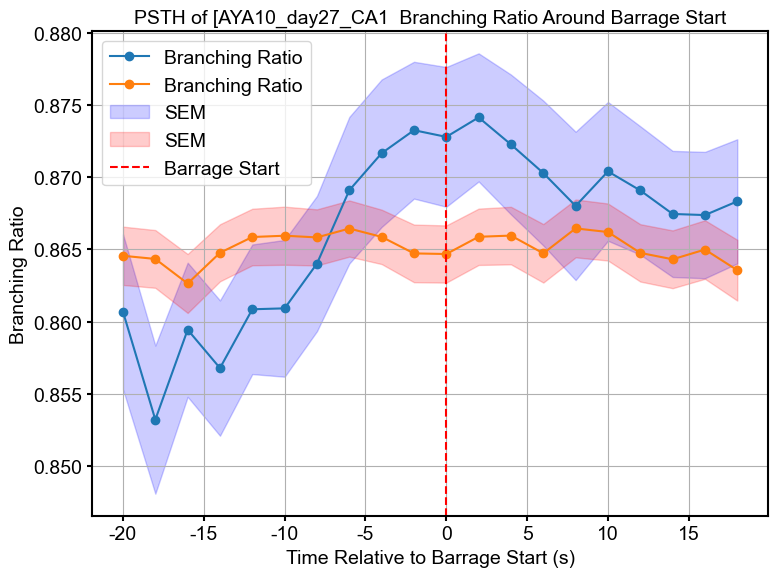

C:\Users\Cornell\AppData\Local\Temp\ipykernel_49992\225425391.py:123: RuntimeWarning: Mean of empty slice
C:\Users\Cornell\AppData\Local\Temp\ipykernel_49992\225425391.py:118: RuntimeWarning: Mean of empty slice
C:\Users\Cornell\AppData\Local\Temp\ipykernel_49992\225425391.py:127: RuntimeWarning: Mean of empty slice


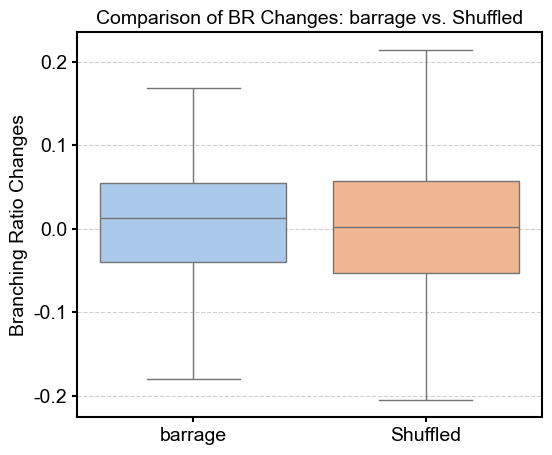

In [266]:

psth_times1, psth_values1, psth_sem1= compute_psth_branching_ratio(centers_time, branching_ratios, barrage_start,window=(-20,20), bin_size=2)
psth_times2, psth_values2, psth_sem2= compute_psth_branching_ratio(centers_time, branching_ratios, barrage_events_random_times,window=(-20,20), bin_size=2)
# Ensure the folder exists
os.makedirs(new_folder_path, exist_ok=True)

# Full path for saving the figure
file_name = f"barrage_PSTH_branchingratio_[{animal_name}_{day}_{brain_region}].png"
save_path = os.path.join(new_folder_path, file_name)
# Plot the PSTH with shadow
plt.figure(figsize=(8, 6))
plt.plot(psth_times1, psth_values1, marker='o', label="Branching Ratio")
plt.plot(psth_times2, psth_values2, marker='o', label="Branching Ratio")
plt.fill_between(psth_times1, psth_values1 - psth_sem1, psth_values1 + psth_sem1, alpha=0.2, color='blue', label="SEM")
plt.fill_between(psth_times2, psth_values2 - psth_sem2, psth_values2 + psth_sem2, alpha=0.2, color='red', label="SEM")
plt.axvline(0, color='red', linestyle='--', label="Barrage Start")
plt.xlabel("Time Relative to Barrage Start (s)")
plt.ylabel("Branching Ratio")
plt.title(f"PSTH of [{animal_name}_{day}_{brain_region}  Branching Ratio Around Barrage Start")
plt.legend()
plt.grid(True)
plt.tight_layout()
# Save the figure
plt.savefig(save_path, dpi=300)
plt.show()

# Define time windows
center_window = (-2.5, 2.5)  # Window for dip around ripple
baseline_windows = [(-20, -20+2.5), (20-2.5, 20)]  # Windows for baseline calculation
br_changes=[]
br_changes_shuffle =[]
# Calculate BR changes
br_changes = calculate_br_changes( branching_ratios,centers_time, barrage_start, center_window, baseline_windows)
br_changes_shuffle = calculate_br_changes(branching_ratios, centers_time, barrage_events_random_times, center_window, baseline_windows)
br_result['barrage_br_changes']=br_changes
br_result['barrage_br_changes_shuffle']=br_changes_shuffle
# Save the results

data = [br_changes, br_changes_shuffle]
labels = ['barrage', 'Shuffled']

    # Create the box plot
plt.figure(figsize=(6, 5))
sns.boxplot(data=data, palette="pastel",showfliers=False)
plt.xticks(ticks=[0, 1], labels=labels)
plt.ylabel("Branching Ratio Changes")
plt.title("Comparison of BR Changes: barrage vs. Shuffled")
plt.grid(axis='y', linestyle='--', alpha=0.6)
file_name = f"barrage_PSTH_br_changes_[{animal_name}_{day}_{brain_region}].png"
# Ensure the folder exists
# Full path for saving the figure
save_path = os.path.join(new_folder_path, file_name)
# Save or show the plot
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()
# import os
# import pickle

# def save_br_result(base_dir, animal_name, day, brain_region, br_result):
#     """
#     Save branching ratio results to a pickle file.

#     File path:
#         {base_dir}/{animal_name}_{day}_{brain_region}_br_changes_non_repetive.pkl
#     """
#     os.makedirs(base_dir, exist_ok=True)

#     file_name = f"{animal_name}_{day}_{brain_region}_br_changes_non_overlap.pkl"
#     file_path = os.path.join(base_dir, file_name)

#     with open(file_path, "wb") as f:
#         pickle.dump(br_result, f)

#     print(f"✅ Saved branching ratio result to: {file_path}")
#     return file_path
# base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio\ripple_barr\branching_ratio"
# save_br_result(base_dir, animal_name, day, brain_region, br_result)


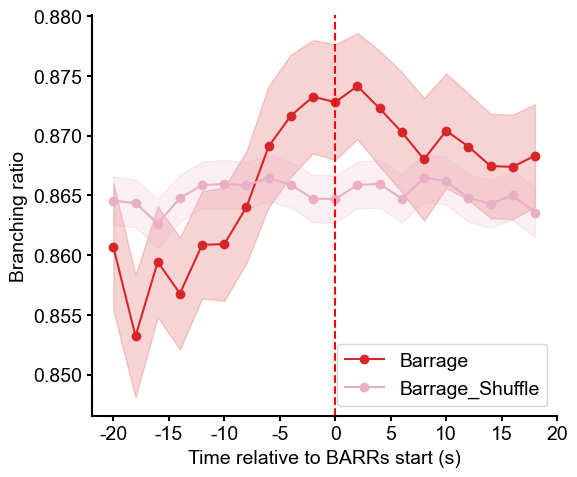

In [267]:
#example for rats  D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio
#basepath = r"V:\data\hpc_ctx_project\HP18\hp18_day36_20250510" 
# Plot the PSTH with shadow
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
plt.figure(figsize=(6, 5))
plt.plot(psth_times1, psth_values1, marker='o', label="Barrage",color="tab:red")
plt.plot(psth_times2, psth_values2, marker='o', label="Barrage_Shuffle",color="#e9afc6ff")
plt.fill_between(psth_times1, psth_values1 - psth_sem1, psth_values1 + psth_sem1, alpha=0.2, color="tab:red", label=None)
plt.fill_between(psth_times2, psth_values2 - psth_sem2, psth_values2 + psth_sem2, alpha=0.2, color="#e9afc6ff", label=None)
plt.axvline(0, color='red', linestyle='--', label=None)
plt.xlabel("Time relative to BARRs start (s)")
plt.xticks(range(-20, 21, 5))   # ticks every 5 s, from -20 to 20
plt.ylabel("Branching ratio")
plt.legend(frameon=True)  # clean legend
plt.tight_layout()
plt.grid(False)
file_name = f"4B_barrage_PSTH_br_changes_[{animal_name}_{day}_{brain_region}].svg"
# Ensure the folder exists
# Full path for saving the figure


# Remove top and right spines
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# example_fig_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\rats"
# save_path = os.path.join(example_fig_path, file_name)
# Save or show the plot
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()